**Find the CSV files attached to your Kaggle notebook**

In [1]:
import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

/kaggle/input/datasets/blastchar/telco-customer-churn/WA_Fn-UseC_-Telco-Customer-Churn.csv


**Import Libraries**

In [2]:
# Import pandas for working with tabular data.
import numpy as np # linear algebra
import pandas as pd # data processing,

# Exploratory Data Analysis

In [3]:
# Load the dataset from your Kaggle input folder.
file_path = "/kaggle/input/datasets/blastchar/telco-customer-churn/WA_Fn-UseC_-Telco-Customer-Churn.csv"
df = pd.read_csv(file_path)

# Display the first five rows.
print("First five rows:")
display(df.head())

# Display the number of rows and columns.
print("Dataset shape:", df.shape)

# Display all column names.
print("Column names:")
print(df.columns.tolist())

# Display column data types and non-missing values.
print("Dataset information:")
df.info()

First five rows:


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


Dataset shape: (7043, 21)
Column names:
['customerID', 'gender', 'SeniorCitizen', 'Partner', 'Dependents', 'tenure', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod', 'MonthlyCharges', 'TotalCharges', 'Churn']
Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   object 
 1   gender            7043 non-null   object 
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   object 
 4   Dependents        7043 non-null   object 
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   object 
 7   MultipleLines     7043 non-null   object 
 8   InternetService   7043 non-null  

In [4]:

# Step 1: Count missing values in every column.
missing_values = df.isnull().sum()

# Display only columns that contain missing values.
print("Columns with missing values:")
display(missing_values[missing_values > 0].sort_values(ascending=False))

# Step 2: Check whether the target column exists.
print("Is the Churn column available?", "Churn" in df.columns)

# Step 3: Count customers in each churn class.
if "Churn" in df.columns:
    print("\nNumber of customers in each Churn class:")
    display(df["Churn"].value_counts(dropna=False))

    # Calculate the percentage of each class.
    print("\nPercentage of customers in each Churn class:")
    display(
        (df["Churn"].value_counts(normalize=True, dropna=False) * 100).round(2)
    )
else:
    print("Please check the spelling and capitalization of your target column.")


Columns with missing values:


Series([], dtype: int64)

Is the Churn column available? True

Number of customers in each Churn class:


Churn
No     5174
Yes    1869
Name: count, dtype: int64


Percentage of customers in each Churn class:


Churn
No     73.46
Yes    26.54
Name: proportion, dtype: float64

In [5]:
# Separate the target from the input features.
X = df.drop(columns=["Churn"])
y = df["Churn"].copy()

# Display the size of the features and target.
print("Features shape:", X.shape)
print("Target shape:", y.shape)

# Display the target categories.
print("Target values:", y.unique())


Features shape: (7043, 20)
Target shape: (7043,)
Target values: ['No' 'Yes']


# Data Preprocessing

In [6]:

# Display the data types of all input features.
print("Feature data types:")
display(X.dtypes)

# Check whether customerID exists in the dataset.
if "customerID" in X.columns:
    print("\nCustomer ID column found.")
else:
    print("\nNo customerID column found.")

# Count categorical and numerical features.
categorical_columns = X.select_dtypes(include=["object", "category"]).columns
numerical_columns = X.select_dtypes(include=["number"]).columns

print("\nNumber of categorical features:", len(categorical_columns))
print("Number of numerical features:", len(numerical_columns))

# Show the names of each group.
print("\nCategorical columns:")
print(categorical_columns.tolist())

print("\nNumerical columns:")
print(numerical_columns.tolist())


Feature data types:


customerID           object
gender               object
SeniorCitizen         int64
Partner              object
Dependents           object
tenure                int64
PhoneService         object
MultipleLines        object
InternetService      object
OnlineSecurity       object
OnlineBackup         object
DeviceProtection     object
TechSupport          object
StreamingTV          object
StreamingMovies      object
Contract             object
PaperlessBilling     object
PaymentMethod        object
MonthlyCharges      float64
TotalCharges         object
dtype: object


Customer ID column found.

Number of categorical features: 17
Number of numerical features: 3

Categorical columns:
['customerID', 'gender', 'Partner', 'Dependents', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod', 'TotalCharges']

Numerical columns:
['SeniorCitizen', 'tenure', 'MonthlyCharges']


**Clean the dataset**

In [7]:

# Work on a copy so the original feature data remains unchanged.
X_clean = X.copy()

# Remove the customer ID if the dataset contains it.
if "customerID" in X_clean.columns:
    X_clean = X_clean.drop(columns=["customerID"])
    print("Removed customerID column.")

# Convert TotalCharges to numeric values if the column exists.
if "TotalCharges" in X_clean.columns:
    X_clean["TotalCharges"] = pd.to_numeric(
        X_clean["TotalCharges"],
        errors="coerce"
    )
    print("Converted TotalCharges to numeric.")

# Check missing values after cleaning.
print("\nMissing values in features:")
display(X_clean.isnull().sum()[X_clean.isnull().sum() > 0])

# Check the updated dataset size.
print("\nCleaned features shape:", X_clean.shape)


Removed customerID column.
Converted TotalCharges to numeric.

Missing values in features:


TotalCharges    11
dtype: int64


Cleaned features shape: (7043, 19)


**Handle missing values.**

In [8]:

# Import tools for filling missing values.
from sklearn.impute import SimpleImputer

# Find numerical and categorical columns.
numerical_columns = X_clean.select_dtypes(include=["number"]).columns
categorical_columns = X_clean.select_dtypes(
    include=["object", "category", "bool"]
).columns

# Fill missing numerical values using each column's median.
if len(numerical_columns) > 0:
    numerical_imputer = SimpleImputer(strategy="median")
    X_clean[numerical_columns] = numerical_imputer.fit_transform(
        X_clean[numerical_columns]
    )

# Fill missing categorical values using the most frequent value.
if len(categorical_columns) > 0:
    categorical_imputer = SimpleImputer(strategy="most_frequent")
    X_clean[categorical_columns] = categorical_imputer.fit_transform(
        X_clean[categorical_columns]
    )

# Verify that missing values have been handled.
print("Total missing values remaining:", X_clean.isnull().sum().sum())
print("Cleaned dataset shape:", X_clean.shape)


Total missing values remaining: 0
Cleaned dataset shape: (7043, 19)


**Convert categorical features into numbers.**

In [9]:
# Convert categorical columns into numerical columns.
X_encoded = pd.get_dummies(
    X_clean,
    columns=X_clean.select_dtypes(
        include=["object", "category", "bool"]
    ).columns,
    drop_first=False,
    dtype=int
)

# Display the first five rows of the encoded dataset.
display(X_encoded.head())

# Check the new dataset dimensions.
print("Encoded features shape:", X_encoded.shape)

# Check whether any text columns remain.
remaining_text_columns = X_encoded.select_dtypes(
    include=["object", "category", "bool"]
).columns

print("Remaining categorical columns:", remaining_text_columns.tolist())


,SeniorCitizen,tenure,MonthlyCharges,TotalCharges,gender_Female,gender_Male,Partner_No,Partner_Yes,Dependents_No,Dependents_Yes,...,StreamingMovies_Yes,Contract_Month-to-month,Contract_One year,Contract_Two year,PaperlessBilling_No,PaperlessBilling_Yes,PaymentMethod_Bank transfer (automatic),PaymentMethod_Credit card (automatic),PaymentMethod_Electronic check,PaymentMethod_Mailed check
0,0.0,1.0,29.85,29.85,1,0,0,1,1,0,...,0,1,0,0,0,1,0,0,1,0
1,0.0,34.0,56.95,1889.50,0,1,1,0,1,0,...,0,0,1,0,1,0,0,0,0,1
2,0.0,2.0,53.85,108.15,0,1,1,0,1,0,...,0,1,0,0,0,1,0,0,0,1
3,0.0,45.0,42.30,1840.75,0,1,1,0,1,0,...,0,0,1,0,1,0,1,0,0,0
4,0.0,2.0,70.70,151.65,1,0,1,0,1,0,...,0,1,0,0,0,1,0,0,1,0


Encoded features shape: (7043, 45)
Remaining categorical columns: []


**Prepare the target and split the dataset.**

In [10]:

from sklearn.model_selection import train_test_split

# Convert the target labels Yes/No into 1/0 if needed.
if set(y.dropna().unique()) == {"Yes", "No"}:
    y_model = y.map({"No": 0, "Yes": 1})
elif y.isin([0, 1]).all():
    y_model = y.copy()
else:
    raise ValueError(
        f"Unexpected Churn values: {y.unique()}. "
        "Check the target labels before continuing."
    )

# First, set aside 15% for the final test set.
X_train_val, X_test, y_train_val, y_test = train_test_split(
    X_encoded,
    y_model,
    test_size=0.15,
    random_state=42,
    stratify=y_model
)

# Split the remaining 85% into training and validation.
# 0.17647 of 85% is approximately 15% of the full dataset.
X_train, X_val, y_train, y_val = train_test_split(
    X_train_val,
    y_train_val,
    test_size=0.17647,
    random_state=42,
    stratify=y_train_val
)

# Display the number of rows in each set.
print("Training set:", X_train.shape)
print("Validation set:", X_val.shape)
print("Test set:", X_test.shape)

# Check the churn proportion in each set.
print("\nChurn percentage in each set:")
print("Training:", round(y_train.mean() * 100, 2), "%")
print("Validation:", round(y_val.mean() * 100, 2), "%")
print("Test:", round(y_test.mean() * 100, 2), "%")


Training set: (4929, 45)
Validation set: (1057, 45)
Test set: (1057, 45)

Churn percentage in each set:
Training: 26.54 %
Validation: 26.58 %
Test: 26.49 %


# Model 01: Logistic Regression

In [11]:

# Import the model and evaluation tools.
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score
)

# Create a pipeline that scales features and trains Logistic Regression.
baseline_model = make_pipeline(
    StandardScaler(),
    LogisticRegression(max_iter=1000, random_state=42)
)

# Train the model using only the training data.
baseline_model.fit(X_train, y_train)

# Predict churn labels for the validation data.
y_val_pred = baseline_model.predict(X_val)

# Get churn probabilities for ROC-AUC evaluation.
y_val_proba = baseline_model.predict_proba(X_val)[:, 1]

# Display the baseline model's validation results.
print("Logistic Regression — Validation Results")
print("----------------------------------------")
print("Accuracy:", round(accuracy_score(y_val, y_val_pred), 3))
print("Precision:", round(precision_score(y_val, y_val_pred, zero_division=0), 3))
print("Recall:", round(recall_score(y_val, y_val_pred, zero_division=0), 3))
print("F1-score:", round(f1_score(y_val, y_val_pred, zero_division=0), 3))
print("ROC-AUC:", round(roc_auc_score(y_val, y_val_proba), 3))


Logistic Regression — Validation Results
----------------------------------------
Accuracy: 0.794
Precision: 0.639
Recall: 0.516
F1-score: 0.571
ROC-AUC: 0.83


**Check class imbalance**

Training set class counts:


Churn
Stayed     3621
Churned    1308
Name: count, dtype: int64


Training set class percentages:


Churn
Stayed     73.46
Churned    26.54
Name: proportion, dtype: float64

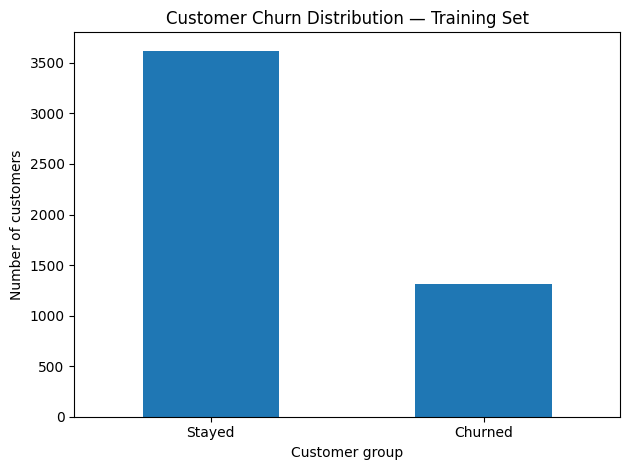

In [12]:

import matplotlib.pyplot as plt

# Count customers who stayed (0) and churned (1).
class_counts = y_train.value_counts().sort_index()

# Calculate each class's percentage.
class_percentages = (
    y_train.value_counts(normalize=True).sort_index() * 100
)

print("Training set class counts:")
display(class_counts.rename(index={0: "Stayed", 1: "Churned"}))

print("\nTraining set class percentages:")
display(class_percentages.rename(index={0: "Stayed", 1: "Churned"}).round(2))

# Plot the class distribution.
class_counts.rename(index={0: "Stayed", 1: "Churned"}).plot(
    kind="bar",
    rot=0
)

plt.title("Customer Churn Distribution — Training Set")
plt.xlabel("Customer group")
plt.ylabel("Number of customers")
plt.tight_layout()
plt.show()


**Improve the baseline before moving to Decision Trees.**

In [13]:

from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score
)

# Train Logistic Regression with balanced class weights.
balanced_model = make_pipeline(
    StandardScaler(),
    LogisticRegression(
        max_iter=1000,
        class_weight="balanced",
        random_state=42
    )
)

balanced_model.fit(X_train, y_train)

# Predict churn on the validation set.
y_balanced_pred = balanced_model.predict(X_val)
y_balanced_proba = balanced_model.predict_proba(X_val)[:, 1]

# Compare the original and balanced models.
results = []

for model_name, model in [
    ("Original Logistic Regression", baseline_model),
    ("Balanced Logistic Regression", balanced_model)
]:
    predictions = model.predict(X_val)
    probabilities = model.predict_proba(X_val)[:, 1]

    results.append({
        "Model": model_name,
        "Accuracy": accuracy_score(y_val, predictions),
        "Precision": precision_score(
            y_val, predictions, zero_division=0
        ),
        "Recall": recall_score(
            y_val, predictions, zero_division=0
        ),
        "F1-score": f1_score(
            y_val, predictions, zero_division=0
        ),
        "ROC-AUC": roc_auc_score(y_val, probabilities)
    })

# Display the comparison, rounded to three decimal places.
import pandas as pd

results_df = pd.DataFrame(results).set_index("Model")
display(results_df.round(3))


,Accuracy,Precision,Recall,F1-score,ROC-AUC
Model,,,,,
Original Logistic Regression,0.794,0.639,0.516,0.571,0.830
Balanced Logistic Regression,0.741,0.508,0.765,0.611,0.829


# Model 02: Decision Tree — Gini criterion.

In [14]:

from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score
)

# Create a Decision Tree using the Gini criterion.
tree_gini = DecisionTreeClassifier(
    criterion="gini",
    max_depth=5,
    class_weight="balanced",
    random_state=42
)

# Train the tree using the training data.
tree_gini.fit(X_train, y_train)

# Predict churn labels on the validation set.
y_tree_pred = tree_gini.predict(X_val)

# Get predicted probabilities for ROC-AUC.
y_tree_proba = tree_gini.predict_proba(X_val)[:, 1]

# Evaluate the model.
print("Decision Tree — Gini Criterion")
print("--------------------------------")
print("Accuracy:", round(accuracy_score(y_val, y_tree_pred), 3))
print("Precision:", round(
    precision_score(y_val, y_tree_pred, zero_division=0), 3
))
print("Recall:", round(
    recall_score(y_val, y_tree_pred, zero_division=0), 3
))
print("F1-score:", round(
    f1_score(y_val, y_tree_pred, zero_division=0), 3
))
print("ROC-AUC:", round(roc_auc_score(y_val, y_tree_proba), 3))


Decision Tree — Gini Criterion
--------------------------------
Accuracy: 0.741
Precision: 0.509
Recall: 0.74
F1-score: 0.603
ROC-AUC: 0.814


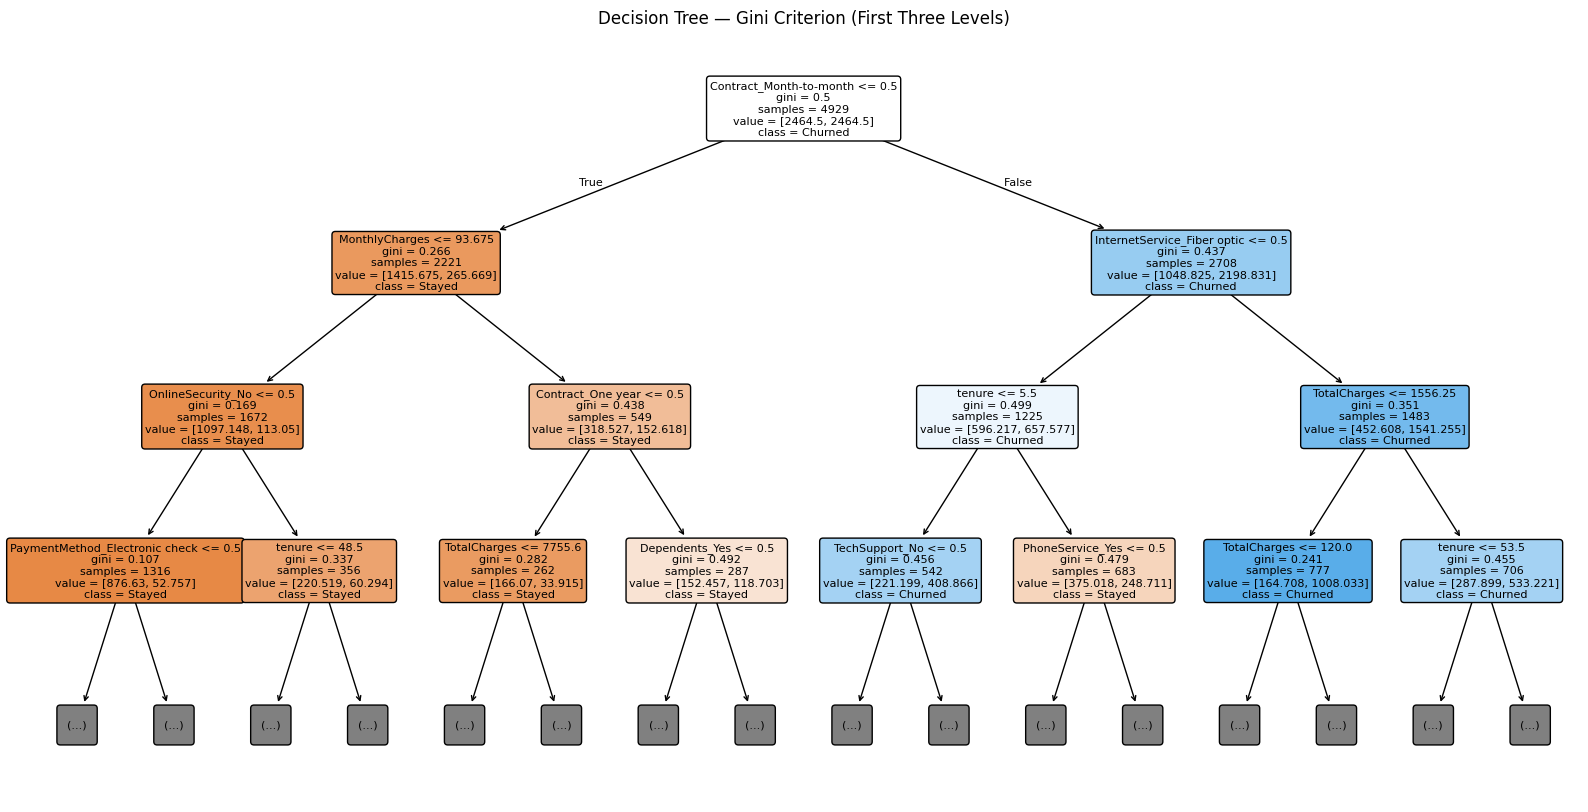

In [15]:

import matplotlib.pyplot as plt
from sklearn.tree import plot_tree

plt.figure(figsize=(20, 10))

plot_tree(
    tree_gini,
    feature_names=X_train.columns.tolist(),
    class_names=["Stayed", "Churned"],
    filled=True,
    rounded=True,
    max_depth=3,
    fontsize=8
)

plt.title("Decision Tree — Gini Criterion (First Three Levels)")
plt.show()


# Model 03: Train a Decision Tree using Entropy.

In [16]:

from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score
)
import pandas as pd

# Create a Decision Tree using Entropy.
tree_entropy = DecisionTreeClassifier(
    criterion="entropy",
    max_depth=5,
    class_weight="balanced",
    random_state=42
)

# Train the model on the same training data.
tree_entropy.fit(X_train, y_train)

# Predict churn on the validation set.
y_entropy_pred = tree_entropy.predict(X_val)
y_entropy_proba = tree_entropy.predict_proba(X_val)[:, 1]

# Collect evaluation metrics.
entropy_results = {
    "Accuracy": accuracy_score(y_val, y_entropy_pred),
    "Precision": precision_score(
        y_val, y_entropy_pred, zero_division=0
    ),
    "Recall": recall_score(
        y_val, y_entropy_pred, zero_division=0
    ),
    "F1-score": f1_score(
        y_val, y_entropy_pred, zero_division=0
    ),
    "ROC-AUC": roc_auc_score(y_val, y_entropy_proba)
}

print("Decision Tree — Entropy Results")
display(pd.DataFrame([entropy_results], index=["Entropy"]).round(3))


Decision Tree — Entropy Results


,Accuracy,Precision,Recall,F1-score,ROC-AUC
Entropy,0.754,0.526,0.747,0.618,0.822


**Compare Gini and Entropy.**

In [17]:

# Calculate metrics for both trained trees.
comparison = []

for name, model in [
    ("Gini", tree_gini),
    ("Entropy", tree_entropy)
]:
    predictions = model.predict(X_val)
    probabilities = model.predict_proba(X_val)[:, 1]

    comparison.append({
        "Criterion": name,
        "Accuracy": accuracy_score(y_val, predictions),
        "Precision": precision_score(
            y_val, predictions, zero_division=0
        ),
        "Recall": recall_score(
            y_val, predictions, zero_division=0
        ),
        "F1-score": f1_score(
            y_val, predictions, zero_division=0
        ),
        "ROC-AUC": roc_auc_score(y_val, probabilities)
    })

comparison_df = pd.DataFrame(comparison).set_index("Criterion")
display(comparison_df.round(3))


,Accuracy,Precision,Recall,F1-score,ROC-AUC
Criterion,,,,,
Gini,0.741,0.509,0.740,0.603,0.814
Entropy,0.754,0.526,0.747,0.618,0.822


**Compare Decision Tree depths and understand overfitting.**

**Train and compare three trees.**

In [18]:

from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score
)
import pandas as pd

# Store the depths we want to compare.
depths = [2, 5, None]  # None means unlimited depth.

depth_results = []

for depth in depths:
    # Create a Gini Decision Tree at the selected depth.
    model = DecisionTreeClassifier(
        criterion="gini",
        max_depth=depth,
        class_weight="balanced",
        random_state=42
    )

    # Train the tree.
    model.fit(X_train, y_train)

    # Predict on training and validation data.
    train_pred = model.predict(X_train)
    val_pred = model.predict(X_val)
    val_proba = model.predict_proba(X_val)[:, 1]

    # Save metrics for comparison.
    depth_results.append({
        "Depth": "Unlimited" if depth is None else depth,
        "Actual depth": model.get_depth(),
        "Training accuracy": accuracy_score(y_train, train_pred),
        "Validation accuracy": accuracy_score(y_val, val_pred),
        "Validation precision": precision_score(
            y_val, val_pred, zero_division=0
        ),
        "Validation recall": recall_score(
            y_val, val_pred, zero_division=0
        ),
        "Validation F1": f1_score(
            y_val, val_pred, zero_division=0
        ),
        "Validation ROC-AUC": roc_auc_score(y_val, val_proba)
    })

# Display all results in one table.
depth_df = pd.DataFrame(depth_results).set_index("Depth")
display(depth_df.round(3))


,Actual depth,Training accuracy,Validation accuracy,Validation precision,Validation recall,Validation F1,Validation ROC-AUC
Depth,,,,,,,
2,2,0.659,0.638,0.413,0.858,0.557,0.770
5,5,0.760,0.741,0.509,0.740,0.603,0.814
Unlimited,27,0.998,0.728,0.488,0.488,0.488,0.650


# Identify the most important features.

**Calculate feature importance.**

In [19]:

import pandas as pd
import matplotlib.pyplot as plt

# Get importance scores from the trained Gini tree.
importance_df = pd.DataFrame({
    "Feature": X_train.columns,
    "Importance": tree_gini.feature_importances_
})

# Sort features from most important to least important.
importance_df = importance_df.sort_values(
    by="Importance",
    ascending=False
)

# Display the top 10 features.
print("Top 10 features for predicting customer churn:")
display(importance_df.head(10).round(4))


Top 10 features for predicting customer churn:


,Feature,Importance
36,Contract_Month-to-month,0.6176
16,InternetService_Fiber optic,0.0984
1,tenure,0.0770
2,MonthlyCharges,0.0623
3,TotalCharges,0.0585
27,TechSupport_No,0.0220
37,Contract_One year,0.0171
11,PhoneService_Yes,0.0116
18,OnlineSecurity_No,0.0111
43,PaymentMethod_Electronic check,0.0076


**Visualize the top 10 features.**

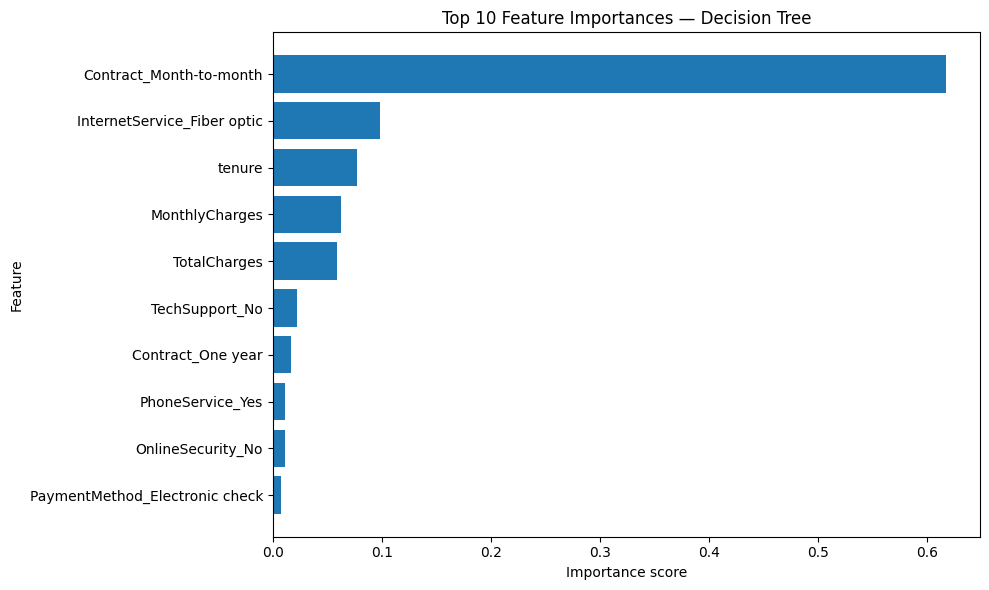

In [20]:

# Select the top 10 features for the chart.
top_features = importance_df.head(10).sort_values(
    by="Importance",
    ascending=True
)

# Create a horizontal bar chart.
plt.figure(figsize=(10, 6))
plt.barh(
    top_features["Feature"],
    top_features["Importance"]
)

plt.title("Top 10 Feature Importances — Decision Tree")
plt.xlabel("Importance score")
plt.ylabel("Feature")
plt.tight_layout()
plt.show()


# Model 04: Train a Bagging Classifier.

In [21]:

from sklearn.ensemble import BaggingClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score
)

# Create Bagging with 100 decision trees.
bagging_model = BaggingClassifier(
    estimator=DecisionTreeClassifier(
        max_depth=5,
        class_weight="balanced",
        random_state=42
    ),
    n_estimators=100,
    random_state=42,
    n_jobs=-1
)

# Train the model using only the training data.
bagging_model.fit(X_train, y_train)

# Predict churn labels for validation customers.
bagging_pred = bagging_model.predict(X_val)

# Get predicted probabilities for customers who may churn.
bagging_proba = bagging_model.predict_proba(X_val)[:, 1]

# Evaluate performance on the validation set.
bagging_results = {
    "Accuracy": accuracy_score(y_val, bagging_pred),
    "Precision": precision_score(y_val, bagging_pred, zero_division=0),
    "Recall": recall_score(y_val, bagging_pred, zero_division=0),
    "F1 Score": f1_score(y_val, bagging_pred, zero_division=0),
    "ROC-AUC": roc_auc_score(y_val, bagging_proba)
}

# Display the evaluation results.
for metric, score in bagging_results.items():
    print(f"{metric}: {score:.4f}")


Accuracy: 0.7512
Precision: 0.5214
Recall: 0.7794
F1 Score: 0.6248
ROC-AUC: 0.8304


# Model 05:Train a Random Forest Classifier.

In [22]:

from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score
)

# Create a Random Forest containing 100 decision trees.
rf_model = RandomForestClassifier(
    n_estimators=100,
    max_depth=5,
    max_features="sqrt",
    class_weight="balanced",
    random_state=42,
    n_jobs=-1
)

# Train the model using the same training data as Bagging.
rf_model.fit(X_train, y_train)

# Predict churn labels for validation customers.
rf_pred = rf_model.predict(X_val)

# Get the probability of the positive class (Churn = 1).
rf_proba = rf_model.predict_proba(X_val)[:, 1]

# Calculate validation performance metrics.
rf_results = {
    "Accuracy": accuracy_score(y_val, rf_pred),
    "Precision": precision_score(y_val, rf_pred, zero_division=0),
    "Recall": recall_score(y_val, rf_pred, zero_division=0),
    "F1 Score": f1_score(y_val, rf_pred, zero_division=0),
    "ROC-AUC": roc_auc_score(y_val, rf_proba)
}

# Display the results.
for metric, score in rf_results.items():
    print(f"{metric}: {score:.4f}")


Accuracy: 0.7228
Precision: 0.4864
Recall: 0.7616
F1 Score: 0.5936
ROC-AUC: 0.8273


**Compare Bagging and Random Forest.**

In [23]:

# Combine the validation results from both models.
comparison_df = pd.DataFrame(
    [bagging_results, rf_results],
    index=["Bagging", "Random Forest"]
)

# Display the scores side by side.
display(comparison_df.round(4))


,Accuracy,Precision,Recall,F1 Score,ROC-AUC
Bagging,0.7512,0.5214,0.7794,0.6248,0.8304
Random Forest,0.7228,0.4864,0.7616,0.5936,0.8273


**Tune Random Forest Hyperparameters.**

In [24]:

from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import roc_auc_score
from itertools import product
import pandas as pd

# Define the settings we want to test.
n_estimators_options = [50, 100, 200]
max_depth_options = [3, 5, 10, None]
max_features_options = ["sqrt", "log2"]

# Store the results from each model.
tuning_results = []

# Try every combination of the settings above.
for n_estimators, max_depth, max_features in product(
    n_estimators_options,
    max_depth_options,
    max_features_options
):
    # Create a Random Forest with the current settings.
    model = RandomForestClassifier(
        n_estimators=n_estimators,
        max_depth=max_depth,
        max_features=max_features,
        class_weight="balanced",
        random_state=42,
        n_jobs=-1
    )

    # Train the model on the training dataset.
    model.fit(X_train, y_train)

    # Get churn probabilities for the validation dataset.
    val_proba = model.predict_proba(X_val)[:, 1]

    # Measure validation ROC-AUC.
    val_roc_auc = roc_auc_score(y_val, val_proba)

    # Save the settings and score.
    tuning_results.append({
        "n_estimators": n_estimators,
        "max_depth": max_depth,
        "max_features": max_features,
        "Validation ROC-AUC": val_roc_auc
    })

# Convert the results into a table.
tuning_df = pd.DataFrame(tuning_results)

# Show the best combinations first.
tuning_df = tuning_df.sort_values(
    by="Validation ROC-AUC",
    ascending=False
).reset_index(drop=True)

display(tuning_df.head(10).round(4))


,n_estimators,max_depth,max_features,Validation ROC-AUC
0,200,10.0,log2,0.8335
1,100,10.0,log2,0.8329
2,50,10.0,log2,0.8326
3,200,10.0,sqrt,0.8317
4,100,10.0,sqrt,0.8298
5,50,10.0,sqrt,0.8282
6,100,5.0,sqrt,0.8273
7,200,5.0,sqrt,0.8271
8,50,5.0,sqrt,0.8271
9,200,5.0,log2,0.8264


**Random Forest Feature Importance and OOB Score.**

**Train Random Forest with OOB enabled.**

In [25]:

from sklearn.ensemble import RandomForestClassifier
import pandas as pd
import matplotlib.pyplot as plt

# Train Random Forest with out-of-bag evaluation enabled.
rf_oob_model = RandomForestClassifier(
    n_estimators=200,
    max_depth=5,
    max_features="sqrt",
    class_weight="balanced",
    oob_score=True,
    random_state=42,
    n_jobs=-1
)

# Fit the model using the training data only.
rf_oob_model.fit(X_train, y_train)

# Display the out-of-bag score.
print(f"OOB Score: {rf_oob_model.oob_score_:.4f}")


OOB Score: 0.7429


**Display the top 10 important features.**

,Feature,Importance
36,Contract_Month-to-month,0.1875
1,tenure,0.1174
38,Contract_Two year,0.1015
18,OnlineSecurity_No,0.0799
27,TechSupport_No,0.0770
16,InternetService_Fiber optic,0.0651
3,TotalCharges,0.0599
43,PaymentMethod_Electronic check,0.0492
2,MonthlyCharges,0.0293
37,Contract_One year,0.0230


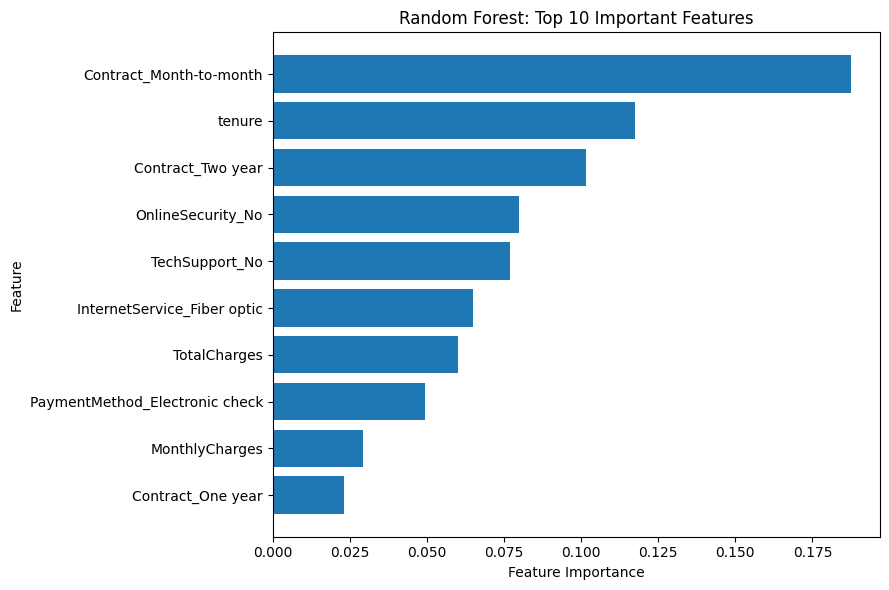

In [26]:

# Pair each feature name with its importance score.
rf_importance_df = pd.DataFrame({
    "Feature": X_train.columns,
    "Importance": rf_oob_model.feature_importances_
})

# Sort features from most important to least important.
rf_importance_df = rf_importance_df.sort_values(
    by="Importance",
    ascending=False
)

# Display the 10 most important features.
display(rf_importance_df.head(10).round(4))

# Plot the top 10 features.
top_features = rf_importance_df.head(10).sort_values(
    by="Importance"
)

plt.figure(figsize=(9, 6))
plt.barh(
    top_features["Feature"],
    top_features["Importance"]
)
plt.xlabel("Feature Importance")
plt.ylabel("Feature")
plt.title("Random Forest: Top 10 Important Features")
plt.tight_layout()
plt.show()


# Model 06: AdaBoost Classifier.

In [27]:

from sklearn.ensemble import AdaBoostClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score
)

# Create a simple decision tree to use as AdaBoost's base model.
ada_tree = DecisionTreeClassifier(
    max_depth=1,
    random_state=42
)

# Create the AdaBoost model.
ada_model = AdaBoostClassifier(
    estimator=ada_tree,
    n_estimators=100,
    learning_rate=0.5,
    random_state=42
)

# Train the model on the training data.
ada_model.fit(X_train, y_train)

# Predict churn labels for validation customers.
ada_pred = ada_model.predict(X_val)

# Get the probability of the positive class (Churn = 1).
ada_proba = ada_model.predict_proba(X_val)[:, 1]

# Calculate validation metrics.
ada_results = {
    "Accuracy": accuracy_score(y_val, ada_pred),
    "Precision": precision_score(y_val, ada_pred, zero_division=0),
    "Recall": recall_score(y_val, ada_pred, zero_division=0),
    "F1 Score": f1_score(y_val, ada_pred, zero_division=0),
    "ROC-AUC": roc_auc_score(y_val, ada_proba)
}

# Display the results.
for metric, score in ada_results.items():
    print(f"{metric}: {score:.4f}")


Accuracy: 0.8013
Precision: 0.6564
Recall: 0.5302
F1 Score: 0.5866
ROC-AUC: 0.8348


# Model 07: Gradient Boosting Classifier

In [28]:

from sklearn.ensemble import GradientBoostingClassifier
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score
)

# Create the Gradient Boosting model.
gb_model = GradientBoostingClassifier(
    n_estimators=100,
    learning_rate=0.1,
    max_depth=3,
    random_state=42
)

# Train the model on the training data.
gb_model.fit(X_train, y_train)

# Predict churn labels for validation customers.
gb_pred = gb_model.predict(X_val)

# Get probabilities for the positive class (Churn = 1).
gb_proba = gb_model.predict_proba(X_val)[:, 1]

# Calculate validation performance metrics.
gb_results = {
    "Accuracy": accuracy_score(y_val, gb_pred),
    "Precision": precision_score(y_val, gb_pred, zero_division=0),
    "Recall": recall_score(y_val, gb_pred, zero_division=0),
    "F1 Score": f1_score(y_val, gb_pred, zero_division=0),
    "ROC-AUC": roc_auc_score(y_val, gb_proba)
}

# Display the results.
for metric, score in gb_results.items():
    print(f"{metric}: {score:.4f}")


Accuracy: 0.8004
Precision: 0.6683
Recall: 0.4947
F1 Score: 0.5685
ROC-AUC: 0.8374


# Model 08: XGBoost Classifier

Check whether XGBoost is installed

In [29]:

# Check whether XGBoost is available.
try:
    import xgboost as xgb
    print("XGBoost version:", xgb.__version__)
except ImportError:
    print("XGBoost is not installed.")


#%pip install xgboost

XGBoost version: 3.4.1


In [30]:

from xgboost import XGBClassifier
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score
)

# Calculate the ratio of non-churners to churners.
negative_count = (y_train == 0).sum()
positive_count = (y_train == 1).sum()

if positive_count == 0:
    raise ValueError("Training data contains no churn examples.")

class_ratio = negative_count / positive_count

# Create the XGBoost model.
xgb_model = XGBClassifier(
    objective="binary:logistic",
    eval_metric="logloss",
    n_estimators=100,
    max_depth=3,
    learning_rate=0.1,
    subsample=0.8,
    colsample_bytree=0.8,
    scale_pos_weight=class_ratio,
    random_state=42,
    n_jobs=-1
)

# Train using the training dataset.
xgb_model.fit(X_train, y_train)

# Predict validation labels and churn probabilities.
xgb_pred = xgb_model.predict(X_val)
xgb_proba = xgb_model.predict_proba(X_val)[:, 1]

# Calculate validation performance metrics.
xgb_results = {
    "Accuracy": accuracy_score(y_val, xgb_pred),
    "Precision": precision_score(y_val, xgb_pred, zero_division=0),
    "Recall": recall_score(y_val, xgb_pred, zero_division=0),
    "F1 Score": f1_score(y_val, xgb_pred, zero_division=0),
    "ROC-AUC": roc_auc_score(y_val, xgb_proba)
}

# Display the results.
for metric, score in xgb_results.items():
    print(f"{metric}: {score:.4f}")


Accuracy: 0.7493
Precision: 0.5191
Recall: 0.7722
F1 Score: 0.6209
ROC-AUC: 0.8359


**Tune Boosting Models with Cross-Validation.**

In [31]:

from sklearn.ensemble import GradientBoostingClassifier
from sklearn.model_selection import GridSearchCV, StratifiedKFold

# Define the settings we want to test.
param_grid = {
    "n_estimators": [50, 100, 150],
    "learning_rate": [0.05, 0.1],
    "max_depth": [2, 3]
}

# Keep the churn/non-churn proportions similar across folds.
cv = StratifiedKFold(
    n_splits=3,
    shuffle=True,
    random_state=42
)

# Create the base model.
gb_base_model = GradientBoostingClassifier(random_state=42)

# Test every combination using cross-validation.
gb_search = GridSearchCV(
    estimator=gb_base_model,
    param_grid=param_grid,
    scoring="roc_auc",
    cv=cv,
    n_jobs=-1,
    verbose=1
)

# Fit using training data only.
gb_search.fit(X_train, y_train)

# Display the best settings and average cross-validation score.
print("Best parameters:", gb_search.best_params_)
print(f"Best CV ROC-AUC: {gb_search.best_score_:.4f}")


Fitting 3 folds for each of 12 candidates, totalling 36 fits
Best parameters: {'learning_rate': 0.05, 'max_depth': 2, 'n_estimators': 150}
Best CV ROC-AUC: 0.8462


**Tune AdaBoost with Cross-Validation.**

In [32]:

from sklearn.ensemble import AdaBoostClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.model_selection import GridSearchCV, StratifiedKFold

# Use simple decision stumps as AdaBoost's base estimators.
ada_base_model = AdaBoostClassifier(
    estimator=DecisionTreeClassifier(
        max_depth=1,
        random_state=42
    ),
    random_state=42
)

# Define the combinations to test.
ada_param_grid = {
    "n_estimators": [50, 100, 150],
    "learning_rate": [0.05, 0.1, 0.5]
}

# Keep class proportions similar in each fold.
ada_cv = StratifiedKFold(
    n_splits=3,
    shuffle=True,
    random_state=42
)

# Search for the best parameter combination.
ada_search = GridSearchCV(
    estimator=ada_base_model,
    param_grid=ada_param_grid,
    scoring="roc_auc",
    cv=ada_cv,
    n_jobs=-1,
    verbose=1
)

# Train and compare the combinations using training data.
ada_search.fit(X_train, y_train)

# Display the best settings and cross-validation score.
print("Best parameters:", ada_search.best_params_)
print(f"Best CV ROC-AUC: {ada_search.best_score_:.4f}")


Fitting 3 folds for each of 9 candidates, totalling 27 fits
Best parameters: {'learning_rate': 0.5, 'n_estimators': 100}
Best CV ROC-AUC: 0.8446


**Tune XGBoost with Cross-Validation.**

In [33]:

from xgboost import XGBClassifier
from sklearn.model_selection import GridSearchCV, StratifiedKFold

# Calculate the class weight using training data only.
negative_count = (y_train == 0).sum()
positive_count = (y_train == 1).sum()

if positive_count == 0:
    raise ValueError("Training data contains no churn examples.")

class_ratio = negative_count / positive_count

# Create the basic XGBoost model.
xgb_base_model = XGBClassifier(
    objective="binary:logistic",
    eval_metric="logloss",
    scale_pos_weight=class_ratio,
    random_state=42,
    n_jobs=1
)

# Define the parameter combinations to test.
xgb_param_grid = {
    "n_estimators": [50, 100, 150],
    "max_depth": [2, 3, 5],
    "learning_rate": [0.05, 0.1]
}

# Use three folds while preserving class proportions.
xgb_cv = StratifiedKFold(
    n_splits=3,
    shuffle=True,
    random_state=42
)

# Search for the best parameter combination.
xgb_search = GridSearchCV(
    estimator=xgb_base_model,
    param_grid=xgb_param_grid,
    scoring="roc_auc",
    cv=xgb_cv,
    n_jobs=-1,
    verbose=1
)

# Train and compare combinations using training data only.
xgb_search.fit(X_train, y_train)

# Display the best settings and average CV score.
print("Best parameters:", xgb_search.best_params_)
print(f"Best CV ROC-AUC: {xgb_search.best_score_:.4f}")


Fitting 3 folds for each of 18 candidates, totalling 54 fits
Best parameters: {'learning_rate': 0.05, 'max_depth': 2, 'n_estimators': 150}
Best CV ROC-AUC: 0.8454


**Plot training versus validation performance.**

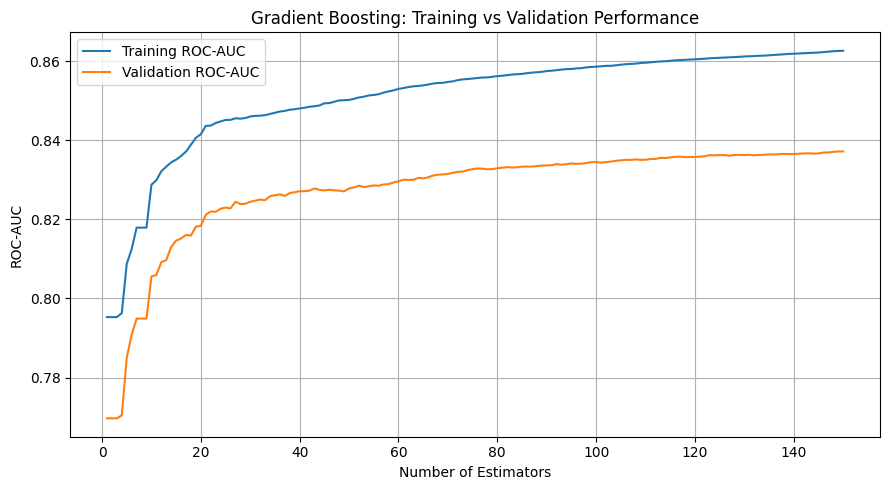

In [34]:

import matplotlib.pyplot as plt
from sklearn.metrics import roc_auc_score

# Use the best Gradient Boosting settings found in Step 24.
best_gb = gb_search.best_estimator_

# Train and validation ROC-AUC scores at each boosting stage.
train_scores = []
val_scores = []

for train_proba, val_proba in zip(
    best_gb.staged_predict_proba(X_train),
    best_gb.staged_predict_proba(X_val)
):
    train_scores.append(
        roc_auc_score(y_train, train_proba[:, 1])
    )
    val_scores.append(
        roc_auc_score(y_val, val_proba[:, 1])
    )

# Plot both scores against the number of estimators.
plt.figure(figsize=(9, 5))
plt.plot(range(1, len(train_scores) + 1), train_scores, label="Training ROC-AUC")
plt.plot(range(1, len(val_scores) + 1), val_scores, label="Validation ROC-AUC")

plt.xlabel("Number of Estimators")
plt.ylabel("ROC-AUC")
plt.title("Gradient Boosting: Training vs Validation Performance")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()


**Plot AdaBoost Training vs Validation Performance.**

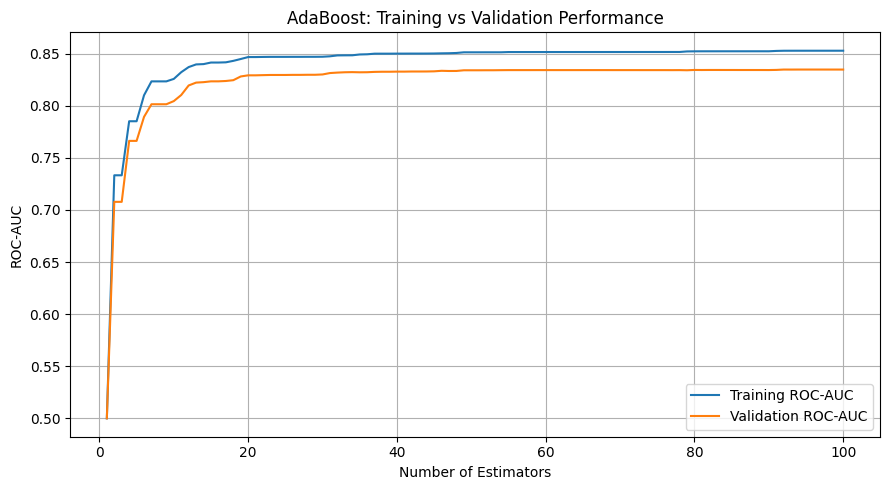

In [35]:

import matplotlib.pyplot as plt
from sklearn.metrics import roc_auc_score

# Get the best AdaBoost model from cross-validation.
best_ada = ada_search.best_estimator_

# Store ROC-AUC scores at each boosting stage.
train_scores = []
val_scores = []

# Calculate performance after adding each estimator.
for train_proba, val_proba in zip(
    best_ada.staged_predict_proba(X_train),
    best_ada.staged_predict_proba(X_val)
):
    train_scores.append(
        roc_auc_score(y_train, train_proba[:, 1])
    )
    val_scores.append(
        roc_auc_score(y_val, val_proba[:, 1])
    )

# Draw the training and validation curves.
plt.figure(figsize=(9, 5))
plt.plot(range(1, len(train_scores) + 1), train_scores, label="Training ROC-AUC")
plt.plot(range(1, len(val_scores) + 1), val_scores, label="Validation ROC-AUC")

plt.xlabel("Number of Estimators")
plt.ylabel("ROC-AUC")
plt.title("AdaBoost: Training vs Validation Performance")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()


**Plot XGBoost Training vs Validation Performance.**

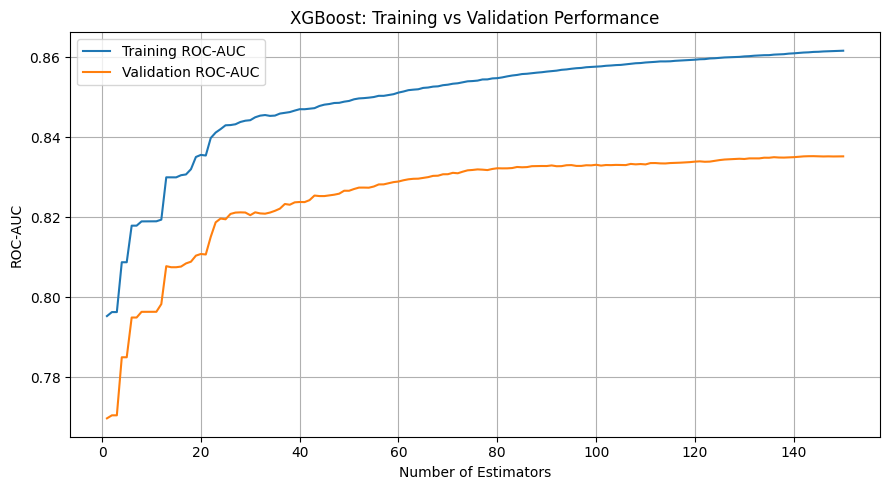

In [36]:

import matplotlib.pyplot as plt

# Get the best XGBoost settings found during cross-validation.
best_xgb = xgb_search.best_estimator_

# Record ROC-AUC during training.
best_xgb.set_params(eval_metric="auc")

# Train again while recording training and validation performance.
best_xgb.fit(
    X_train,
    y_train,
    eval_set=[
        (X_train, y_train),
        (X_val, y_val)
    ],
    verbose=False
)

# Retrieve the scores recorded at each boosting stage.
xgb_history = best_xgb.evals_result()

train_scores = xgb_history["validation_0"]["auc"]
val_scores = xgb_history["validation_1"]["auc"]

# Plot both performance curves.
plt.figure(figsize=(9, 5))
plt.plot(range(1, len(train_scores) + 1), train_scores, label="Training ROC-AUC")
plt.plot(range(1, len(val_scores) + 1), val_scores, label="Validation ROC-AUC")

plt.xlabel("Number of Estimators")
plt.ylabel("ROC-AUC")
plt.title("XGBoost: Training vs Validation Performance")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()


# Build a Model Comparison Table.

In [50]:

import pandas as pd

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler

# Start from the original, unencoded dataset.
X_raw = df.drop(columns=["Churn", "customerID"], errors="ignore").copy()

# Convert TotalCharges to numbers; blank or invalid values become missing.
if "TotalCharges" in X_raw.columns:
    X_raw["TotalCharges"] = pd.to_numeric(
        X_raw["TotalCharges"], errors="coerce"
    )

# Convert the target into binary labels: No = 0, Yes = 1.
y_raw = df["Churn"].map({"No": 0, "Yes": 1})

# Check that the target was converted correctly.
if y_raw.isna().any():
    raise ValueError("Unexpected or missing values found in Churn.")

# Split into 70% training, 15% validation, and 15% test data.
X_train_raw, X_temp_raw, y_train, y_temp = train_test_split(
    X_raw, y_raw,
    test_size=0.30,
    random_state=42,
    stratify=y_raw
)

X_val_raw, X_test_raw, y_val, y_test = train_test_split(
    X_temp_raw, y_temp,
    test_size=0.50,
    random_state=42,
    stratify=y_temp
)

# Identify numeric and categorical columns using training data.
numeric_columns = X_train_raw.select_dtypes(
    include=["number"]
).columns.tolist()

categorical_columns = X_train_raw.select_dtypes(
    exclude=["number"]
).columns.tolist()

# Fill missing numeric values and scale numeric features.
numeric_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

# Fill missing categories and convert categories into numeric columns.
categorical_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

# Apply the correct preprocessing to each column type.
preprocessor = ColumnTransformer([
    ("numeric", numeric_pipeline, numeric_columns),
    ("categorical", categorical_pipeline, categorical_columns)
])

# Learn preprocessing rules from training data only.
X_train = preprocessor.fit_transform(X_train_raw)

# Apply the learned rules to validation and test data.
X_val = preprocessor.transform(X_val_raw)
X_test = preprocessor.transform(X_test_raw)

# Verify the split sizes and transformed feature counts.
print("Training set:", X_train.shape)
print("Validation set:", X_val.shape)
print("Test set:", X_test.shape)
print("Training churn rate:", round(y_train.mean(), 3))
print("Validation churn rate:", round(y_val.mean(), 3))
print("Test churn rate:", round(y_test.mean(), 3))


Training set: (4930, 45)
Validation set: (1056, 45)
Test set: (1057, 45)
Training churn rate: 0.265
Validation churn rate: 0.265
Test churn rate: 0.266


**Retrain the Baseline and Decision Tree Models.**

In [38]:

import pandas as pd

from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score
)

# Store trained models so we can reuse them later.
models = {
    "Logistic Regression": LogisticRegression(max_iter=1000),
    "Balanced Logistic Regression": LogisticRegression(
        max_iter=1000,
        class_weight="balanced"
    ),
    "Decision Tree - Gini": DecisionTreeClassifier(
        criterion="gini",
        max_depth=5,
        class_weight="balanced",
        random_state=42
    ),
    "Decision Tree - Entropy": DecisionTreeClassifier(
        criterion="entropy",
        max_depth=5,
        class_weight="balanced",
        random_state=42
    )
}

# Store validation results for comparison.
validation_results = []

for model_name, model in models.items():

    # Train each model using only the training data.
    model.fit(X_train, y_train)

    # Predict churn labels and churn probabilities on validation data.
    predictions = model.predict(X_val)
    probabilities = model.predict_proba(X_val)[:, 1]

    # Calculate the five required evaluation metrics.
    validation_results.append({
        "Model": model_name,
        "Accuracy": accuracy_score(y_val, predictions),
        "Precision": precision_score(
            y_val, predictions, zero_division=0
        ),
        "Recall": recall_score(
            y_val, predictions, zero_division=0
        ),
        "F1": f1_score(y_val, predictions, zero_division=0),
        "ROC-AUC": roc_auc_score(y_val, probabilities)
    })

# Display results with four decimal places.
validation_df = pd.DataFrame(validation_results)

print(validation_df.round(4).to_string(index=False))


                       Model  Accuracy  Precision  Recall     F1  ROC-AUC
         Logistic Regression    0.8059     0.6459  0.5929 0.6182   0.8453
Balanced Logistic Regression    0.7396     0.5055  0.8143 0.6238   0.8447
        Decision Tree - Gini    0.7064     0.4694  0.8214 0.5974   0.8347
     Decision Tree - Entropy    0.7064     0.4694  0.8214 0.5974   0.8343


**Retrain Bagging and Random Forest.**

In [39]:

import pandas as pd

from sklearn.ensemble import BaggingClassifier, RandomForestClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score
)

# Create the Bagging model using decision trees.
bagging_model = BaggingClassifier(
    estimator=DecisionTreeClassifier(
        max_depth=5,
        class_weight="balanced",
        random_state=42
    ),
    n_estimators=100,
    bootstrap=True,
    oob_score=True,
    n_jobs=-1,
    random_state=42
)

# Create the Random Forest model.
rf_model = RandomForestClassifier(
    n_estimators=100,
    max_depth=5,
    max_features="sqrt",
    class_weight="balanced",
    bootstrap=True,
    oob_score=True,
    n_jobs=-1,
    random_state=42
)

# Store the models so we can reuse them later.
ensemble_models = {
    "Bagging": bagging_model,
    "Random Forest": rf_model
}

ensemble_results = []

for model_name, model in ensemble_models.items():

    # Train using only the training data.
    model.fit(X_train, y_train)

    # Predict on the validation data.
    predictions = model.predict(X_val)
    probabilities = model.predict_proba(X_val)[:, 1]

    # Calculate evaluation metrics.
    ensemble_results.append({
        "Model": model_name,
        "Accuracy": accuracy_score(y_val, predictions),
        "Precision": precision_score(
            y_val, predictions, zero_division=0
        ),
        "Recall": recall_score(
            y_val, predictions, zero_division=0
        ),
        "F1": f1_score(y_val, predictions, zero_division=0),
        "ROC-AUC": roc_auc_score(y_val, probabilities),
        "OOB Score": model.oob_score_
    })

# Add these results to our existing validation comparison.
new_results_df = pd.DataFrame(ensemble_results)

validation_df = pd.concat(
    [
        validation_df[
            ~validation_df["Model"].isin(new_results_df["Model"])
        ],
        new_results_df.drop(columns=["OOB Score"])
    ],
    ignore_index=True
)

# Display the two ensemble models' validation scores.
print(new_results_df.round(4).to_string(index=False))

# Display the out-of-bag scores separately.
print("\nOut-of-Bag (OOB) Scores:")
for model_name, model in ensemble_models.items():
    print(f"{model_name}: {model.oob_score_:.4f}")


        Model  Accuracy  Precision  Recall     F1  ROC-AUC  OOB Score
      Bagging    0.7566     0.5264  0.8179 0.6406   0.8482     0.7515
Random Forest    0.7282     0.4924  0.8071 0.6116   0.8421     0.7398

Out-of-Bag (OOB) Scores:
Bagging: 0.7515
Random Forest: 0.7398


**Retrain AdaBoost, Gradient Boosting, and XGBoost.**

In [40]:

import pandas as pd

from sklearn.ensemble import AdaBoostClassifier, GradientBoostingClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score
)
from xgboost import XGBClassifier

# Calculate class weight using training data only.
negative_count = (y_train == 0).sum()
positive_count = (y_train == 1).sum()

if positive_count == 0:
    raise ValueError("Training data contains no churn examples.")

class_ratio = negative_count / positive_count

# Create AdaBoost with simple decision trees.
ada_model = AdaBoostClassifier(
    estimator=DecisionTreeClassifier(
        max_depth=1,
        random_state=42
    ),
    n_estimators=100,
    learning_rate=0.1,
    random_state=42
)

# Create Gradient Boosting.
gb_model = GradientBoostingClassifier(
    n_estimators=100,
    learning_rate=0.1,
    max_depth=3,
    random_state=42
)

# Create XGBoost with a weight for the minority class.
xgb_model = XGBClassifier(
    n_estimators=100,
    max_depth=3,
    learning_rate=0.1,
    scale_pos_weight=class_ratio,
    objective="binary:logistic",
    eval_metric="logloss",
    random_state=42,
    n_jobs=-1
)

# Keep the models together for easier comparison.
boosting_models = {
    "AdaBoost": ada_model,
    "Gradient Boosting": gb_model,
    "XGBoost": xgb_model
}

boosting_results = []

for model_name, model in boosting_models.items():

    # Train the model using training data only.
    model.fit(X_train, y_train)

    # Predict labels and churn probabilities on validation data.
    predictions = model.predict(X_val)
    probabilities = model.predict_proba(X_val)[:, 1]

    # Calculate the five required evaluation metrics.
    boosting_results.append({
        "Model": model_name,
        "Accuracy": accuracy_score(y_val, predictions),
        "Precision": precision_score(
            y_val, predictions, zero_division=0
        ),
        "Recall": recall_score(
            y_val, predictions, zero_division=0
        ),
        "F1": f1_score(y_val, predictions, zero_division=0),
        "ROC-AUC": roc_auc_score(y_val, probabilities)
    })

# Save the results in a DataFrame.
boosting_results_df = pd.DataFrame(boosting_results)

# Add or replace these models in the overall comparison.
validation_df = pd.concat(
    [
        validation_df[
            ~validation_df["Model"].isin(
                boosting_results_df["Model"]
            )
        ],
        boosting_results_df
    ],
    ignore_index=True
)

# Display boosting model results.
print(boosting_results_df.round(4).to_string(index=False))

# Display all models trained so far.
print("\nOverall Validation Comparison:")
print(
    validation_df
    .sort_values("ROC-AUC", ascending=False)
    .round(4)
    .to_string(index=False)
)


            Model  Accuracy  Precision  Recall     F1  ROC-AUC
         AdaBoost    0.7898     0.6576  0.4321 0.5216   0.8417
Gradient Boosting    0.8011     0.6562  0.5250 0.5833   0.8477
          XGBoost    0.7500     0.5179  0.8286 0.6374   0.8474

Overall Validation Comparison:
                       Model  Accuracy  Precision  Recall     F1  ROC-AUC
                     Bagging    0.7566     0.5264  0.8179 0.6406   0.8482
           Gradient Boosting    0.8011     0.6562  0.5250 0.5833   0.8477
                     XGBoost    0.7500     0.5179  0.8286 0.6374   0.8474
         Logistic Regression    0.8059     0.6459  0.5929 0.6182   0.8453
Balanced Logistic Regression    0.7396     0.5055  0.8143 0.6238   0.8447
               Random Forest    0.7282     0.4924  0.8071 0.6116   0.8421
                    AdaBoost    0.7898     0.6576  0.4321 0.5216   0.8417
        Decision Tree - Gini    0.7064     0.4694  0.8214 0.5974   0.8347
     Decision Tree - Entropy    0.7064     0.4694 

**Tune AdaBoost Using Cross-Validation.**

In [41]:

from sklearn.ensemble import AdaBoostClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.model_selection import GridSearchCV, StratifiedKFold

# Create the base AdaBoost model.
ada_base_model = AdaBoostClassifier(
    estimator=DecisionTreeClassifier(
        max_depth=1,
        random_state=42
    ),
    random_state=42
)

# Define the settings we want to compare.
ada_param_grid = {
    "n_estimators": [50, 100, 150],
    "learning_rate": [0.05, 0.1, 0.5]
}

# Split training data into three stratified folds.
ada_cv = StratifiedKFold(
    n_splits=3,
    shuffle=True,
    random_state=42
)

# Search for the best settings using ROC-AUC.
ada_search = GridSearchCV(
    estimator=ada_base_model,
    param_grid=ada_param_grid,
    scoring="roc_auc",
    cv=ada_cv,
    n_jobs=-1,
    verbose=1
)

# Tune using training data only.
ada_search.fit(X_train, y_train)

# Display the best settings and cross-validation score.
print("Best AdaBoost parameters:", ada_search.best_params_)
print(f"Best CV ROC-AUC: {ada_search.best_score_:.4f}")

# Save the best tuned model for later comparison.
best_ada = ada_search.best_estimator_


Fitting 3 folds for each of 9 candidates, totalling 27 fits
Best AdaBoost parameters: {'learning_rate': 0.5, 'n_estimators': 150}
Best CV ROC-AUC: 0.8477


In [42]:

from sklearn.ensemble import AdaBoostClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.model_selection import GridSearchCV, StratifiedKFold

# Create the base AdaBoost model.
ada_base_model = AdaBoostClassifier(
    estimator=DecisionTreeClassifier(
        max_depth=1,
        random_state=42
    ),
    random_state=42
)

# Define the settings we want to compare.
ada_param_grid = {
    "n_estimators": [50, 100, 150],
    "learning_rate": [0.05, 0.1, 0.5]
}

# Split training data into three stratified folds.
ada_cv = StratifiedKFold(
    n_splits=3,
    shuffle=True,
    random_state=42
)

# Search for the best settings using ROC-AUC.
ada_search = GridSearchCV(
    estimator=ada_base_model,
    param_grid=ada_param_grid,
    scoring="roc_auc",
    cv=ada_cv,
    n_jobs=-1,
    verbose=1
)

# Tune using training data only.
ada_search.fit(X_train, y_train)

# Display the best settings and cross-validation score.
print("Best AdaBoost parameters:", ada_search.best_params_)
print(f"Best CV ROC-AUC: {ada_search.best_score_:.4f}")

# Save the best tuned model for later comparison.
best_ada = ada_search.best_estimator_


Fitting 3 folds for each of 9 candidates, totalling 27 fits
Best AdaBoost parameters: {'learning_rate': 0.5, 'n_estimators': 150}
Best CV ROC-AUC: 0.8477


**Tune XGBoost using cross-validation**

In [43]:

from xgboost import XGBClassifier
from sklearn.model_selection import GridSearchCV, StratifiedKFold

# Calculate the ratio to help handle class imbalance.
negative_count = (y_train == 0).sum()
positive_count = (y_train == 1).sum()

if positive_count == 0:
    raise ValueError("No churn-positive examples found in training data.")

class_ratio = negative_count / positive_count

# Create the base XGBoost model.
xgb_base_model = XGBClassifier(
    objective="binary:logistic",
    eval_metric="logloss",
    scale_pos_weight=class_ratio,
    random_state=42,
    n_jobs=1
)

# Parameters to compare.
xgb_param_grid = {
    "n_estimators": [50, 100, 150],
    "max_depth": [3, 5],
    "learning_rate": [0.05, 0.1]
}

# Use three-fold cross-validation.
xgb_cv = StratifiedKFold(
    n_splits=3,
    shuffle=True,
    random_state=42
)

xgb_search = GridSearchCV(
    estimator=xgb_base_model,
    param_grid=xgb_param_grid,
    scoring="roc_auc",
    cv=xgb_cv,
    n_jobs=-1,
    verbose=1
)

# Train and select the best parameter combination.
xgb_search.fit(X_train, y_train)

best_xgb = xgb_search.best_estimator_

print("Best XGBoost parameters:", xgb_search.best_params_)
print(f"Best CV ROC-AUC: {xgb_search.best_score_:.4f}")


Fitting 3 folds for each of 12 candidates, totalling 36 fits
Best XGBoost parameters: {'learning_rate': 0.05, 'max_depth': 3, 'n_estimators': 100}
Best CV ROC-AUC: 0.8459


**Plot the required boosting-model performance curves**

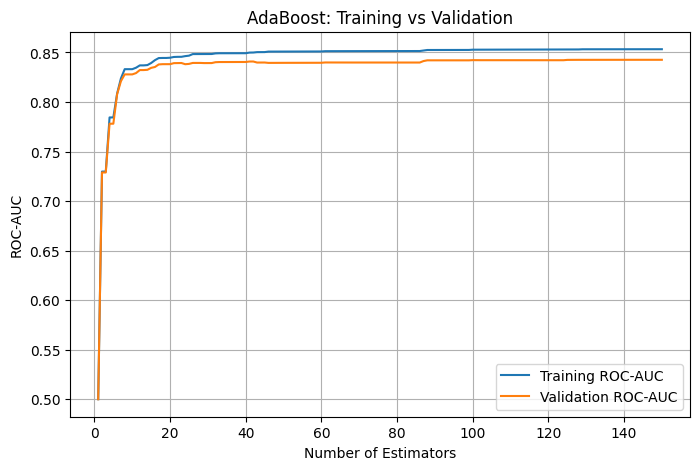

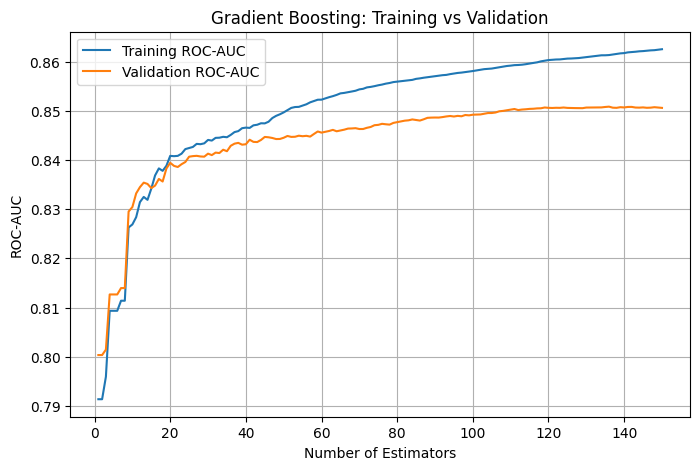

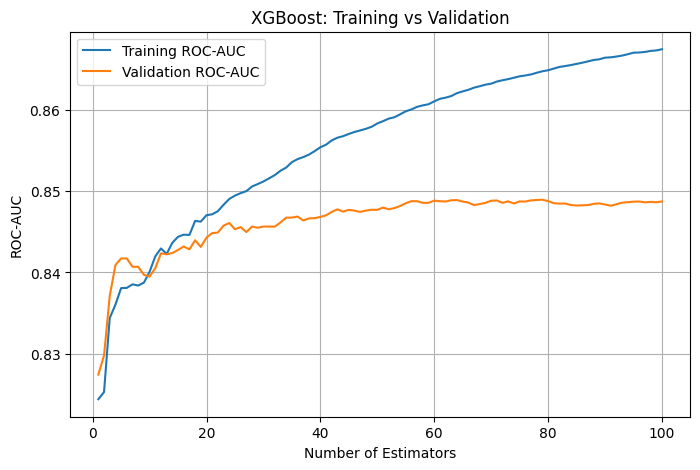

In [44]:

import matplotlib.pyplot as plt
from sklearn.metrics import roc_auc_score

# Use dense input for Gradient Boosting if preprocessing produced sparse data.
X_train_gb = X_train.toarray() if hasattr(X_train, "toarray") else X_train
X_val_gb = X_val.toarray() if hasattr(X_val, "toarray") else X_val

# Use the best tuned models.
best_ada = ada_search.best_estimator_
best_gb = gb_search.best_estimator_
best_xgb = xgb_search.best_estimator_

# Prepare each model with its suitable input data.
plot_models = {
    "AdaBoost": (best_ada, X_train, X_val),
    "Gradient Boosting": (best_gb, X_train_gb, X_val_gb),
    "XGBoost": (best_xgb, X_train, X_val)
}

for model_name, (model, X_tr, X_va) in plot_models.items():
    # Train the selected model on the training split.
    model.fit(X_tr, y_train)

    # Get the ROC-AUC score at each estimator count.
    train_scores = []
    val_scores = []

    if model_name == "AdaBoost":
        stages_train = model.staged_predict_proba(X_tr)
        stages_val = model.staged_predict_proba(X_va)

        for train_prob, val_prob in zip(stages_train, stages_val):
            train_scores.append(roc_auc_score(y_train, train_prob[:, 1]))
            val_scores.append(roc_auc_score(y_val, val_prob[:, 1]))

    elif model_name == "Gradient Boosting":
        stages_train = model.staged_predict_proba(X_tr)
        stages_val = model.staged_predict_proba(X_va)

        for train_prob, val_prob in zip(stages_train, stages_val):
            train_scores.append(roc_auc_score(y_train, train_prob[:, 1]))
            val_scores.append(roc_auc_score(y_val, val_prob[:, 1]))

    else:
        # XGBoost exposes evaluation scores during staged training.
        from xgboost import XGBClassifier

        plot_xgb = XGBClassifier(**{
            **model.get_params(),
            "n_estimators": model.get_params()["n_estimators"],
            "eval_metric": "auc"
        })

        plot_xgb.fit(
            X_tr, y_train,
            eval_set=[(X_tr, y_train), (X_va, y_val)],
            verbose=False
        )

        eval_results = plot_xgb.evals_result()
        train_scores = eval_results["validation_0"]["auc"]
        val_scores = eval_results["validation_1"]["auc"]

    estimator_counts = range(1, len(train_scores) + 1)

    plt.figure(figsize=(8, 5))
    plt.plot(estimator_counts, train_scores, label="Training ROC-AUC")
    plt.plot(estimator_counts, val_scores, label="Validation ROC-AUC")
    plt.xlabel("Number of Estimators")
    plt.ylabel("ROC-AUC")
    plt.title(f"{model_name}: Training vs Validation")
    plt.legend()
    plt.grid(True)
    plt.show()


# Evaluate all models on the test set

In [45]:

import pandas as pd
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score
)

# Combine all nine models required for comparison.
all_models = {
    **models,
    **ensemble_models,
    "AdaBoost": best_ada,
    "Gradient Boosting": best_gb,
    "XGBoost": best_xgb
}

# Gradient Boosting requires dense input in many scikit-learn versions.
X_test_gb = (
    X_test.toarray()
    if hasattr(X_test, "toarray")
    else X_test
)

test_results = []

for model_name, model in all_models.items():
    # Use dense data only for Gradient Boosting.
    if model_name == "Gradient Boosting":
        X_tr, X_te = X_train_gb, X_test_gb
    else:
        X_tr, X_te = X_train, X_test

    # Fit using training data, then evaluate on test data.
    model.fit(X_tr, y_train)
    predictions = model.predict(X_te)
    probabilities = model.predict_proba(X_te)[:, 1]

    test_results.append({
        "Model": model_name,
        "Accuracy": accuracy_score(y_test, predictions),
        "Precision": precision_score(
            y_test, predictions, zero_division=0
        ),
        "Recall": recall_score(
            y_test, predictions, zero_division=0
        ),
        "F1": f1_score(
            y_test, predictions, zero_division=0
        ),
        "ROC-AUC": roc_auc_score(y_test, probabilities)
    })

# Display the best F1 scores first.
test_results_df = pd.DataFrame(test_results)
test_results_df = test_results_df.sort_values(
    by="F1", ascending=False
).reset_index(drop=True)

display(test_results_df.round(4))


,Model,Accuracy,Precision,Recall,F1,ROC-AUC
0,Balanced Logistic Regression,0.7474,0.5165,0.7794,0.6213,0.8446
1,Bagging,0.7502,0.5209,0.7544,0.6163,0.8359
2,XGBoost,0.7455,0.5143,0.7687,0.6163,0.8384
3,Random Forest,0.7351,0.5012,0.7616,0.6045,0.8345
4,Logistic Regression,0.8117,0.6898,0.5302,0.5996,0.8448
5,Decision Tree - Entropy,0.7143,0.4768,0.7687,0.5886,0.8212
6,Decision Tree - Gini,0.7143,0.4768,0.7687,0.5886,0.8214
7,AdaBoost,0.8032,0.6682,0.5160,0.5823,0.8384
8,Gradient Boosting,0.7947,0.6616,0.4662,0.5470,0.8387


Step 39: Create the SHAP summary plot

In [46]:
%pip install shap

Note: you may need to restart the kernel to use updated packages.


Best model by test ROC-AUC: Logistic Regression


/tmp/ipykernel_605/712785035.py:61: FutureWarning: The NumPy global RNG was seeded by calling `np.random.seed`. In a future version this function will no longer use the global RNG. Pass `rng` explicitly to opt-in to the new behaviour and silence this warning.
  shap.summary_plot(


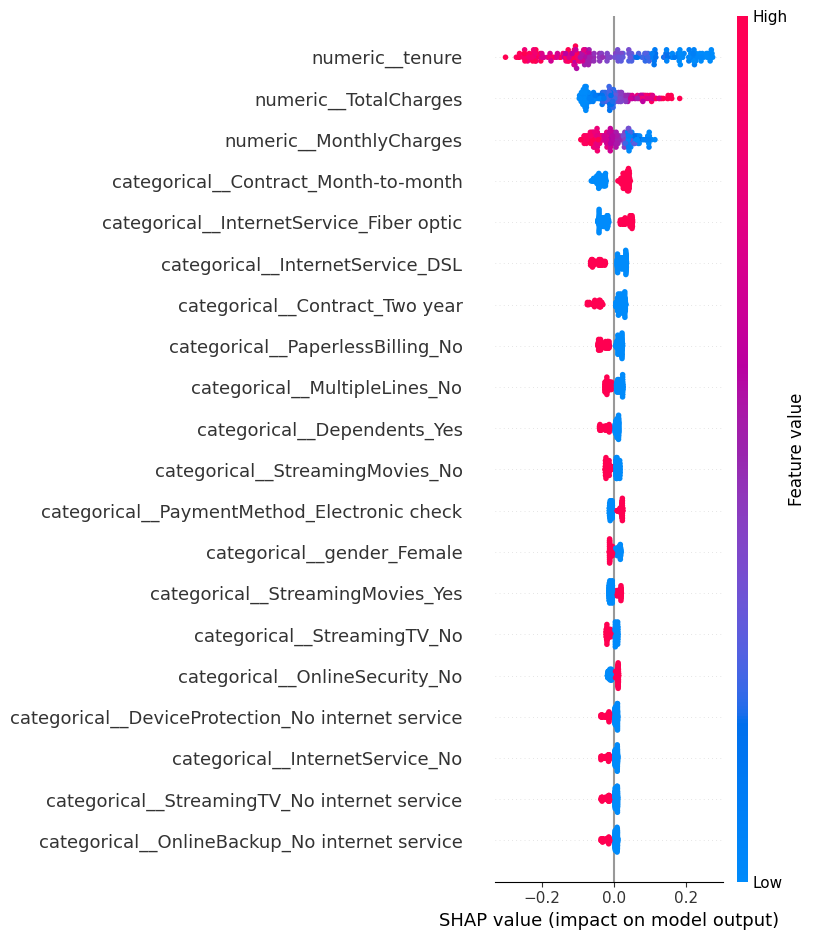

In [47]:

import shap
import numpy as np
import pandas as pd

# Select the model with the highest test ROC-AUC.
best_model_name = test_results_df.loc[
    test_results_df["ROC-AUC"].idxmax(), "Model"
]
best_model = all_models[best_model_name]

print("Best model by test ROC-AUC:", best_model_name)

# Prepare data in a format SHAP can explain.
if best_model_name == "Gradient Boosting":
    X_train_shap = X_train_gb
    X_test_shap = X_test_gb
else:
    X_train_shap = X_train
    X_test_shap = X_test

# Get the transformed feature names.
feature_names = preprocessor.get_feature_names_out()

# Use a manageable sample for the explanation.
X_explain = X_test_shap[:200]

# TreeExplainer supports tree-based models.
if best_model_name in [
    "Decision Tree - Gini",
    "Decision Tree - Entropy",
    "Bagging",
    "Random Forest",
    "AdaBoost",
    "Gradient Boosting",
    "XGBoost"
]:
    explainer = shap.TreeExplainer(best_model)
    shap_values = explainer.shap_values(X_explain)

    # Handle different SHAP output formats.
    if isinstance(shap_values, list):
        shap_values = shap_values[1] if len(shap_values) > 1 else shap_values[0]
    elif isinstance(shap_values, np.ndarray) and shap_values.ndim == 3:
        shap_values = shap_values[:, :, 1]

    shap.summary_plot(
        shap_values,
        X_explain,
        feature_names=feature_names,
        show=True
    )
else:
    # Model-agnostic explanation for logistic regression.
    background = X_train_shap[:100]
    explainer = shap.Explainer(
        best_model.predict_proba,
        background
    )
    shap_values = explainer(X_explain)

    shap.summary_plot(
        shap_values[:, :, 1],
        X_explain,
        feature_names=feature_names,
        show=True
    )


**Prepare the one-page project report**

In [48]:

# 1. Identify the best model by test ROC-AUC.
best_row = test_results_df.loc[
    test_results_df["ROC-AUC"].idxmax()
]

print("BEST MODEL")
print("Model:", best_row["Model"])
print("Test Accuracy:", round(best_row["Accuracy"], 4))
print("Test Precision:", round(best_row["Precision"], 4))
print("Test Recall:", round(best_row["Recall"], 4))
print("Test F1:", round(best_row["F1"], 4))
print("Test ROC-AUC:", round(best_row["ROC-AUC"], 4))

# 2. Compare the two decision-tree criteria.
print("\nGINI VS ENTROPY")
display(
    test_results_df[
        test_results_df["Model"].isin([
            "Decision Tree - Gini",
            "Decision Tree - Entropy"
        ])
    ].reset_index(drop=True)
)

# 3. Compare Bagging and Random Forest.
print("\nBAGGING VS RANDOM FOREST")
display(
    test_results_df[
        test_results_df["Model"].isin([
            "Bagging",
            "Random Forest"
        ])
    ].reset_index(drop=True)
)

# 4. Extract the three most important features from SHAP values.
import numpy as np
import pandas as pd

shap_array = (
    shap_values.values
    if hasattr(shap_values, "values")
    else shap_values
)

# Handle common SHAP output formats.
if isinstance(shap_array, list):
    shap_array = shap_array[1] if len(shap_array) > 1 else shap_array[0]

if shap_array.ndim == 3:
    shap_array = shap_array[:, :, 1]

mean_shap = np.abs(shap_array).mean(axis=0)

top_features = pd.DataFrame({
    "Feature": feature_names,
    "Mean Absolute SHAP": mean_shap
}).sort_values(
    "Mean Absolute SHAP",
    ascending=False
).head(3)

print("\nTOP THREE FEATURES INFLUENCING PREDICTIONS")
display(top_features.reset_index(drop=True))


BEST MODEL
Model: Logistic Regression
Test Accuracy: 0.8117
Test Precision: 0.6898
Test Recall: 0.5302
Test F1: 0.5996
Test ROC-AUC: 0.8448

GINI VS ENTROPY


,Model,Accuracy,Precision,Recall,F1,ROC-AUC
0,Decision Tree - Entropy,0.714286,0.476821,0.768683,0.588556,0.821248
1,Decision Tree - Gini,0.714286,0.476821,0.768683,0.588556,0.821443



BAGGING VS RANDOM FOREST


,Model,Accuracy,Precision,Recall,F1,ROC-AUC
0,Bagging,0.750237,0.520885,0.754448,0.616279,0.835895
1,Random Forest,0.735099,0.501171,0.761566,0.604520,0.834485



TOP THREE FEATURES INFLUENCING PREDICTIONS


,Feature,Mean Absolute SHAP
0,numeric__tenure,0.141216
1,numeric__TotalCharges,0.053985
2,numeric__MonthlyCharges,0.044369


**Create requirements.txt**

In [49]:

import sklearn
import pandas
import numpy
import matplotlib
import shap
import xgboost

# Record the versions used by this notebook.
requirements = f"""pandas=={pandas.__version__}
numpy=={numpy.__version__}
scikit-learn=={sklearn.__version__}
matplotlib=={matplotlib.__version__}
shap=={shap.__version__}
xgboost=={xgboost.__version__}
"""

print(requirements)

# Save the dependency list as a file.
with open("requirements.txt", "w") as file:
    file.write(requirements)

print("requirements.txt created successfully.")


pandas==2.3.3
numpy==2.1.3
scikit-learn==1.6.1
matplotlib==3.10.0
shap==0.52.0
xgboost==3.4.1

requirements.txt created successfully.
